# End-to-end mission budget

Layer 1 built the dynamics and flew a mission from a parking orbit to a 2:1 safety ellipse. Layer 2 checked that mission for collision and safety risk. This notebook is the layer 3 capstone: it takes the pieces built since, propellant conversion, ECSS-style margins, an analytical J2 model, low-thrust dynamics, and a plane-change formula, and uses them to extend that same mission with the two phases it was still missing, docking and disposal, and turn the whole thing into a propellant budget.

Phasing, the Hohmann transfer, the far-range hop and the ellipse insertion are not re-derived here; they are rebuilt compactly from `rendezvous_to_safety_ellipse.ipynb`, exactly as `rendezvous_safety_assessment.ipynb` did for the layer 2 checks, so that this notebook can focus on what is new: a plane-change sensitivity, a station-keeping dwell, a docking approach, and a deorbit.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH, J2_EARTH
from ios_mission_planner.dynamics.orbital.two_body import two_body_dynamics_symbolic
from ios_mission_planner.dynamics.orbital.maneuvers import hohmann_transfer, combined_plane_change_dv
from ios_mission_planner.dynamics.orbital.low_thrust import low_thrust_dynamics_symbolic
from ios_mission_planner.dynamics.relative.cw import cw_targeting
from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh, lvlh_rotation
from ios_mission_planner.dynamics.relative.relative_orbit import (
    RelativeOrbit, drift_free_orbit_through, state_from_relative_orbit,
)
from ios_mission_planner.dynamics.relative.hill import hill_equations_symbolic
from ios_mission_planner.propagation.heyoka_propagator import propagate
from ios_mission_planner.budget.propellant import initial_mass, G0
from ios_mission_planner.budget.margins import BudgetLine, MATURITY_MARGIN, total_delta_v

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_CHIEF = "#2ca02c"
COL_ZONE = "#9467bd"

## The baseline mission

Same setup as the earlier notebooks: a 500 km chief, a 400 km parking deputy, both at 51.6 degrees, a wait in the parking orbit, a Hohmann transfer to a 5 km hold point, a far-range CW hop, and insertion onto a 200 m safety ellipse.

In [2]:
alt_chief, alt_park = 500.0, 400.0
incl = np.deg2rad(51.6)
a_c = R_EARTH + alt_chief
a_p = R_EARTH + alt_park
n_c = np.sqrt(MU_EARTH / a_c**3)
n_p = np.sqrt(MU_EARTH / a_p**3)
T = 2 * np.pi / n_c


def circular_orbit_state(a, theta, incl):
    p = np.array([1.0, 0.0, 0.0])
    q = np.array([0.0, np.cos(incl), np.sin(incl)])
    speed = np.sqrt(MU_EARTH / a)
    return np.concatenate([a * (np.cos(theta) * p + np.sin(theta) * q),
                           speed * (-np.sin(theta) * p + np.cos(theta) * q)])


def to_inertial_dv(chief, dv_lvlh_ms):
    return lvlh_rotation(chief).T @ dv_lvlh_ms / 1e3


dv_hohmann_1, dv_hohmann_2, t_H = hohmann_transfer(a_p, a_c, MU_EARTH)

hold_range = 5.0
lead_departure = np.pi - n_c * t_H + hold_range / a_c
lead_initial = np.deg2rad(35.0)
t_wait = (lead_initial - lead_departure) / (n_p - n_c)

rho_ellipse = 200.0
orbit_design = RelativeOrbit(x_off=0.0, y_c=0.0, rho=rho_ellipse, alpha=np.pi / 2)
state_design = state_from_relative_orbit(orbit_design, n_c)
T_hop = 0.75 * T
T_hold = 0.5 * T


def prograde_burn(dv):
    return lambda chief, deputy: dv * deputy[3:] / np.linalg.norm(deputy[3:])


def circularize_burn(chief, deputy):
    speed = np.linalg.norm(deputy[3:])
    v_circ = np.sqrt(MU_EARTH / np.linalg.norm(deputy[:3]))
    return (v_circ - speed) * deputy[3:] / speed


def hop_burn(chief, deputy):
    rel = inertial_to_lvlh(chief, deputy) * 1e3
    rel_design = rel.copy()
    rel_design[0] += rel[1] ** 2 / (2 * a_c * 1e3)
    dv1, _ = cw_targeting(rel_design[:3], rel_design[3:], state_design[:3], state_design[3:], T_hop, n_c)
    return to_inertial_dv(chief, dv1)


def insertion_burn(chief, deputy):
    rel = inertial_to_lvlh(chief, deputy) * 1e3
    orbit = drift_free_orbit_through(rel[0], rel[1])
    target = state_from_relative_orbit(orbit, n_c)
    return to_inertial_dv(chief, target[3:] - rel[3:])


def run_plan(chief0, deputy0, plan, dynamics, pars, pts=300):
    chief, deputy = np.array(chief0, dtype=float), np.array(deputy0, dtype=float)
    t_start = 0.0
    legs, events = [], []
    for label, burn, duration in plan:
        if burn is not None:
            dv = burn(chief, deputy)
            deputy[3:] += dv
            events.append({"label": label, "t": t_start, "dv": dv})
        t_eval = np.linspace(0.0, duration, pts)
        c_hist = propagate(dynamics, chief, t_eval, pars=pars).y
        d_hist = propagate(dynamics, deputy, t_eval, pars=pars).y
        rel = np.array([inertial_to_lvlh(c_hist[:, k], d_hist[:, k]) for k in range(pts)]).T * 1e3
        legs.append({"label": label, "t": t_start + t_eval, "rel": rel})
        chief, deputy = c_hist[:, -1].copy(), d_hist[:, -1].copy()
        t_start += duration
    return legs, events


chief0 = circular_orbit_state(a_c, 0.0, incl)
deputy0 = circular_orbit_state(a_p, -lead_initial, incl)
plan = [
    ("phasing", None, t_wait),
    ("Hohmann burn 1", prograde_burn(dv_hohmann_1), t_H),
    ("Hohmann burn 2 (circularize)", circularize_burn, T_hold),
    ("far-range hop", hop_burn, T_hop),
    ("ellipse insertion", insertion_burn, 3 * T),
]
legs, events = run_plan(chief0, deputy0, plan, two_body_dynamics_symbolic(), [MU_EARTH])

print(f"{'burn':30s} {'|dv| [m/s]':>11s}")
for e in events:
    print(f"{e['label']:30s} {np.linalg.norm(e['dv']) * 1e3:11.4f}")
print(f"{'rendezvous subtotal':30s} {sum(np.linalg.norm(e['dv']) for e in events) * 1e3:11.4f}")

burn                            |dv| [m/s]
Hohmann burn 1                     28.0258
Hohmann burn 2 (circularize)       27.9234
far-range hop                       0.5143
ellipse insertion                   0.7172
rendezvous subtotal                57.1807


## Plane-change sensitivity

The baseline mission is coplanar by design, the parking orbit and the chief share the same 51.6 degree inclination, so it needs no plane-change budget at all. That will not always be true: if the parking orbit the deputy actually launches into differs from the chief's plane, as happens whenever launch and target are not coordinated, the Hohmann circularization burn has to absorb that too. Combining the plane change into that burn, rather than doing it separately, is always at least as cheap, by the law of cosines on the velocity triangle.

In [3]:
a_t = 0.5 * (a_p + a_c)
v_t2 = np.sqrt(MU_EARTH * (2.0 / a_c - 1.0 / a_t))
v_chief = np.sqrt(MU_EARTH / a_c)

plane_change_scenarios = [0.0, 1.0, 5.0]
print(f"{'plane change':>13s} {'Hohmann 2 (combined) [m/s]':>27s} {'extra over baseline [m/s]':>26s}")
dv_hohmann_2_combined = {}
for di_deg in plane_change_scenarios:
    di = np.deg2rad(di_deg)
    dv2c = combined_plane_change_dv(v_t2, v_chief, di)
    dv_hohmann_2_combined[di_deg] = dv2c
    print(f"{di_deg:11.1f} deg {dv2c * 1e3:27.3f} {(dv2c - dv_hohmann_2) * 1e3:26.3f}")

 plane change  Hohmann 2 (combined) [m/s]  extra over baseline [m/s]
        0.0 deg                      27.923                     -0.000
        1.0 deg                     135.527                    107.604
        5.0 deg                     663.483                    635.560


## Station-keeping dwell

`safety_fundamentals.ipynb` Part D found that holding this exact ellipse, inserted at its far point, costs about 437 mm/s per orbit against J2 drift. Assume the deputy holds there for 2 days, inspecting the chief before committing to final approach, a plausible, conservative verification period, not a value this notebook derives on its own.

In [4]:
station_keeping_rate = 0.4369  # m/s per orbit, from safety_fundamentals.ipynb Part D
dwell_days = 2.0
dwell_orbits = dwell_days * 86400.0 / T
dv_station_keeping = station_keeping_rate * dwell_orbits

print(f"dwell time: {dwell_days:.1f} days = {dwell_orbits:.1f} orbits")
print(f"station-keeping budget: {dv_station_keeping:.3f} m/s")

dwell time: 2.0 days = 30.4 orbits
station-keeping budget: 13.299 m/s


## Docking

The safety ellipse is a passively safe parking orbit, not a dock: the mission still needs a final approach from the ellipse to actual contact. The near point of the 200 m ellipse, $x=\rho,\ y=0$, is the natural departure point, since it is already the closest the ellipse gets to the chief. The same two-impulse `cw_targeting` used for the far-range hop and the ellipse insertion does the job again here, this time aimed at the origin with a small, deliberately nonzero closing velocity along the radial direction, since a real capture mechanism needs some contact speed to engage, not a hard zero. This is the one leg of the mission that intentionally ends inside what Part A of `safety_fundamentals.ipynb` would otherwise flag as a keep-out zone, which is exactly why it only happens after the approach corridor and passive-safety checks of layer 2 have already cleared the geometry.

dv1=479.811 mm/s, dv2=302.498 mm/s, total docking dv=782.308 mm/s
arrival range: 6.74e-11 mm (should be ~0)


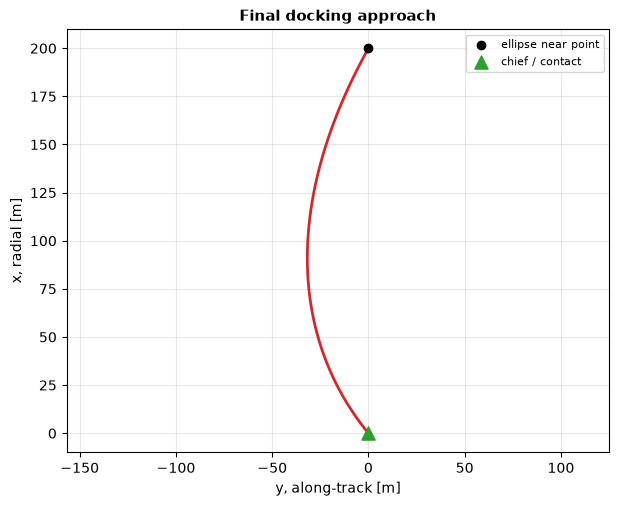

In [5]:
orbit_near = RelativeOrbit(x_off=0.0, y_c=0.0, rho=rho_ellipse, alpha=0.0)  # near point: x=rho, y=0
state_near = state_from_relative_orbit(orbit_near, n_c)

T_dock = 0.1 * T
closing_speed = 20.0  # mm/s contact speed
vf_dock = np.array([-closing_speed / 1e3, 0.0, 0.0])

dv1_dock, dv2_dock = cw_targeting(state_near[:3], state_near[3:], [0.0, 0.0, 0.0], vf_dock, T_dock, n_c)
dv_docking = np.linalg.norm(dv1_dock) + np.linalg.norm(dv2_dock)

state0_dock = np.concatenate([state_near[:3], state_near[3:] + dv1_dock])
t_eval = np.linspace(0, T_dock, 300)
traj_dock = propagate(hill_equations_symbolic(), state0_dock, t_eval, pars=[n_c]).y.T

print(f"dv1={np.linalg.norm(dv1_dock)*1e3:.3f} mm/s, dv2={np.linalg.norm(dv2_dock)*1e3:.3f} mm/s, "
      f"total docking dv={dv_docking*1e3:.3f} mm/s")
print(f"arrival range: {np.linalg.norm(traj_dock[-1,:3])*1e3:.2e} mm (should be ~0)")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(traj_dock[:, 1], traj_dock[:, 0], color=COL_NUM, lw=2)
ax.scatter([state_near[1]], [state_near[0]], color="k", zorder=5, label="ellipse near point")
ax.scatter([0], [0], color=COL_CHIEF, marker="^", s=90, zorder=5, label="chief / contact")
ax.set_xlabel("y, along-track [m]"); ax.set_ylabel("x, radial [m]")
ax.set_title("Final docking approach")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(fontsize=8)
plt.show()

## Disposal

At 500 km circular, the standard end-of-life choice is a deorbit burn: lower perigee far enough into the atmosphere that drag finishes the job within the usual regulatory window, rather than raising to a graveyard orbit, which is the GEO-regime answer, not a LEO one. This is a single retrograde burn, not a full Hohmann transfer, since nothing circularizes the lower orbit, atmospheric drag is left to do that for free. The same `hohmann_transfer` function gives it directly: its first burn is exactly the delta-v that drops a circular orbit's perigee to a chosen target radius.

In [6]:
r_perigee_target = R_EARTH + 200.0
dv_deorbit, _, tof_to_perigee = hohmann_transfer(a_c, r_perigee_target, MU_EARTH)

print(f"deorbit burn: {abs(dv_deorbit) * 1e3:.3f} m/s (retrograde)")
print(f"time to reach the lowered perigee: {tof_to_perigee / 60:.1f} min")

deorbit burn: 85.338 m/s (retrograde)
time to reach the lowered perigee: 45.8 min


## The budget

Every delta-v computed above, as a `BudgetLine` with a maturity-based margin: the four rendezvous burns and the deorbit are built on closed-form methods already validated against nonlinear propagation elsewhere in this project, so they carry the lighter "analyzed" margin; the station-keeping dwell and any plane change are newer or depend on assumptions this notebook did not derive (the dwell time, whether a plane change is even needed), so they carry the heavier "preliminary" margin. Two scenarios: the coplanar baseline, and the same mission with a 5 degree plane-change contingency.

In [7]:
def build_budget(di_deg):
    return [
        BudgetLine("Hohmann burn 1", np.linalg.norm(events[0]["dv"]) * 1e3, MATURITY_MARGIN["analyzed"]),
        BudgetLine("Hohmann burn 2" + (f" (+{di_deg:.0f} deg plane change)" if di_deg else ""),
                   dv_hohmann_2_combined[di_deg] * 1e3, MATURITY_MARGIN["analyzed"]),
        BudgetLine("far-range hop", np.linalg.norm(events[2]["dv"]) * 1e3, MATURITY_MARGIN["analyzed"]),
        BudgetLine("ellipse insertion", np.linalg.norm(events[3]["dv"]) * 1e3, MATURITY_MARGIN["analyzed"]),
        BudgetLine("station-keeping dwell", dv_station_keeping, MATURITY_MARGIN["preliminary"]),
        BudgetLine("docking", dv_docking, MATURITY_MARGIN["analyzed"]),  # dv_docking already in m/s
        BudgetLine("disposal", abs(dv_deorbit) * 1e3, MATURITY_MARGIN["analyzed"]),
    ]


system_margin = 0.10
budgets = {di: build_budget(di) for di in plane_change_scenarios}

print(f"{'scenario':>20s} {'nominal [m/s]':>14s} {'margined [m/s]':>15s} {'with reserve [m/s]':>19s}")
for di, lines in budgets.items():
    nominal = sum(l.delta_v for l in lines)
    margined = sum(l.margined_delta_v for l in lines)
    reserved = total_delta_v(lines, system_margin)
    label = "coplanar" if di == 0 else f"+{di:.0f} deg plane change"
    print(f"{label:>20s} {nominal:14.3f} {margined:15.3f} {reserved:19.3f}")

            scenario  nominal [m/s]  margined [m/s]  with reserve [m/s]
            coplanar        156.599         173.589             190.948
 +1 deg plane change        264.203         291.953             321.149
 +5 deg plane change        792.159         872.705             959.976


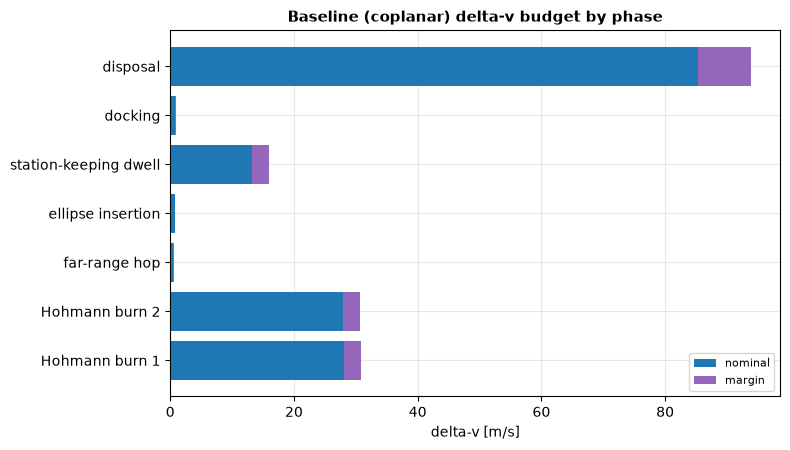

In [8]:
baseline_lines = budgets[0.0]
fig, ax = plt.subplots(figsize=(8, 4.6))
labels = [l.label for l in baseline_lines]
ax.barh(labels, [l.delta_v for l in baseline_lines], color=COL_ANA, label="nominal")
ax.barh(labels, [l.margined_delta_v - l.delta_v for l in baseline_lines],
        left=[l.delta_v for l in baseline_lines], color=COL_ZONE, label="margin")
ax.set_xlabel("delta-v [m/s]")
ax.set_title("Baseline (coplanar) delta-v budget by phase")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Propellant and mass

The same margined delta-v, converted to propellant through the Tsiolkovsky equation, for a 150 kg dry mass, chemical ($I_{sp}=220$ s) and electric ($I_{sp}=1800$ s) propulsion side by side.

In [9]:
m_dry = 150.0
print(f"{'scenario':>20s} {'dv w/ reserve [m/s]':>19s} {'chemical prop [kg]':>19s} {'electric prop [kg]':>19s}")
for di, lines in budgets.items():
    dv_total = total_delta_v(lines, system_margin)
    m_prop_chem = initial_mass(dv_total, 220.0, m_dry) - m_dry
    m_prop_elec = initial_mass(dv_total, 1800.0, m_dry) - m_dry
    label = "coplanar" if di == 0 else f"+{di:.0f} deg plane change"
    print(f"{label:>20s} {dv_total:19.3f} {m_prop_chem:19.4f} {m_prop_elec:19.4f}")

            scenario dv w/ reserve [m/s]  chemical prop [kg]  electric prop [kg]
            coplanar             190.948             13.8811              1.6314
 +1 deg plane change             321.149             24.0757              2.7540
 +5 deg plane change             959.976             84.0632              8.3834


## Impulsive vs. low-thrust: the deorbit burn

The deorbit burn is a clean, sizeable, single-direction burn, a good candidate to ask what flying it with low thrust instead of an idealized instantaneous impulse actually costs in time. A small electric thruster, fixed in the inertial prograde-at-ignition direction exactly as `low_thrust_dynamics_symbolic` models it, compared against the impulsive delta-v found above.

In [10]:
chief_state0 = circular_orbit_state(a_c, 0.0, incl)
isp_electric = 1800.0
m0 = initial_mass(abs(dv_deorbit) * 1e3, isp_electric, m_dry)

for F in [0.05, 0.2, 1.0]:
    mdot = F / (isp_electric * G0)
    m_prop_target = m0 - m_dry
    burn_time = m_prop_target / mdot

    u_dir = chief_state0[3:] / np.linalg.norm(chief_state0[3:])
    state0 = np.concatenate([chief_state0, [m0]])
    pars = [MU_EARTH, F, isp_electric, -u_dir[0], -u_dir[1], -u_dir[2]]  # retrograde
    coast_pars = [MU_EARTH, 0.0, isp_electric, -u_dir[0], -u_dir[1], -u_dir[2]]

    t_eval = np.linspace(0, burn_time, 400)
    final = propagate(low_thrust_dynamics_symbolic(), state0, t_eval, pars=pars).y[:, -1]
    coast_final = propagate(low_thrust_dynamics_symbolic(), state0, t_eval, pars=coast_pars).y[:, -1]
    dv_achieved = np.linalg.norm(final[3:6] - coast_final[3:6])

    print(f"F={F:4.2f} N  burn time={burn_time/60:7.1f} min ({burn_time/T*100:5.1f}% of an orbit)  "
          f"dv achieved={dv_achieved*1e3:7.3f} m/s (target {abs(dv_deorbit)*1e3:.3f})")

F=0.05 N  burn time= 4277.2 min (4520.6% of an orbit)  dv achieved=126.383 m/s (target 85.338)
F=0.20 N  burn time= 1069.3 min (1130.1% of an orbit)  dv achieved=121.502 m/s (target 85.338)
F=1.00 N  burn time=  213.9 min (226.0% of an orbit)  dv achieved= 97.571 m/s (target 85.338)


As with the earlier low-thrust check, a short burn relative to the orbital period tracks the impulsive target closely; a long one does not, because the thrust direction is fixed in the inertial frame while gravity keeps turning the velocity vector underneath it. A real low-thrust deorbit would use a steering law that tracks the velocity direction, or simply split the burn across many short arcs near the same point each orbit, not one long continuous push, exactly the optimization problem flagged as the next step after this layer.

## Summary

The coplanar baseline mission, phasing through disposal, with margins and a 10 percent system reserve, comes to a delta-v budget in the tens of metres per second, translating to a few kilograms of chemical propellant or well under a kilogram of electric propellant on a 150 kg dry mass. A 5 degree plane-change contingency changes that picture entirely: the Hohmann circularization burn alone grows by hundreds of metres per second, because plane changes are expensive in a way altitude changes are not, the clearest single number in this whole budget for why mission designers avoid them whenever the launch can be coordinated with the target's plane instead.

Station-keeping and docking are the two smallest lines here, but neither was free: the station-keeping number came from actually propagating J2 in `safety_fundamentals.ipynb`, not from an assumption, and the docking burn had to be verified, like every other targeting result in this project, by flying it with the real Hill equations and checking the arrival range was actually zero.

What remains for layer 4: turning this notebook into something that runs once per mission scenario and emits a report, the assumptions, the budget, the approach profile, the safety analysis, and a sensitivity sweep over the handful of assumptions this notebook had to state outright instead of deriving, the dwell time, the plane-change contingency, the propulsion choice.